# DIVINO — robustness studies

Companion to `DIVINO_main_study.ipynb`. It reuses the same frozen operator and helper conventions and
writes its figures and tables to `../results/`. The studies are:

- sensitivity to the mask smoothing length `tau`
- local-minimum sensitivity from repeated inverse starts
- out-of-distribution star and triangle cavities
- spatially correlated measurement noise
- operator versus adjoint finite-element cost break-even
- cut-cell / perimeter-correction convergence
- two-cavity proximity diagnostic

Run from the `notebooks/` directory after creating `../src/checkpoints/pino.pt`.

In [1]:
import os, sys, time, platform, warnings, math
from pathlib import Path
ROOT = Path('..').resolve()   # repo root (run this notebook from notebooks/)
SRC = ROOT / 'src'
sys.path.insert(0, str(SRC))

import numpy as np
import pandas as pd
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.spatial import Delaunay
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.path as mpath
import matplotlib.tri as mtri
from matplotlib.colors import Normalize

import torch
from skfem import MeshTri, Basis, FacetBasis, ElementTriP1, BilinearForm, LinearForm, asm, condense, solve
from skfem.helpers import dot, grad

import divino, fem
warnings.filterwarnings('ignore')
%matplotlib inline

DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

mpl.rcParams.update({
    'figure.dpi':130, 'savefig.dpi':300, 'savefig.bbox':'tight', 'savefig.pad_inches':0.02,
    'font.family':'serif', 'font.serif':['Times New Roman','DejaVu Serif'], 'mathtext.fontset':'cm',
    'font.size':10, 'axes.titlesize':10.5, 'axes.labelsize':10, 'xtick.labelsize':8.5,
    'ytick.labelsize':8.5, 'legend.fontsize':8.5, 'axes.linewidth':0.8, 'lines.linewidth':1.6,
    'axes.grid':True, 'grid.alpha':0.22, 'grid.linewidth':0.5,
    'axes.spines.top':False, 'axes.spines.right':False})
COL1, COL2 = 3.5, 7.2
OKABE = ['#0072B2','#D55E00','#009E73','#CC79A7','#E69F00','#56B4E9','#000000']
CMAP_T = plt.cm.viridis.copy(); CMAP_T.set_bad('white')
CMAP_E = plt.cm.magma.copy();   CMAP_E.set_bad('white')

ASSET = ROOT / 'results'
FIGDIR = ASSET / 'figures'
TABDIR = ASSET / 'tables'
DATDIR = ASSET / 'data'
for d in (FIGDIR, TABDIR, DATDIR): d.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    fig.savefig(FIGDIR / f'{name}.pdf')
    fig.savefig(FIGDIR / f'{name}.png', dpi=300)

def savetab(df, name):
    df.to_csv(TABDIR / f'{name}.csv', index=False)
    return df

def _envint(k, d): return int(os.environ.get(k, d))
def _envfloat(k, d): return float(os.environ.get(k, d))
def _envlist(k, d, cast=float):
    raw = os.environ.get(k, d)
    return [cast(x.strip()) for x in raw.split(',') if x.strip()]

CFG = dict(
    NHI=_envint('NHI', 200),
    FEM_HF_HI=_envfloat('FEM_HF_HI', 0.009),
    FEM_HF=_envfloat('FEM_HF', 0.012),
    REVIEW_INV_REPS=_envint('REVIEW_INV_REPS', _envint('INV_REPS', 8)),
    REVIEW_INV_STEPS=_envint('REVIEW_INV_STEPS', _envint('INV_STEPS', 250)),
    REVIEW_STARTS=_envint('REVIEW_STARTS', 4),
    TAU_VALUES=_envlist('TAU_VALUES', '0.01,0.05,0.10,0.15,0.20', float),
    NOISE_SIGMA=_envfloat('NOISE_SIGMA', 0.01),
    CORR_LENGTH=_envfloat('CORR_LENGTH', 0.12),
    ADJOINT_ITERS=_envint('ADJOINT_ITERS', 100),
    TRAIN_TIME_S=_envfloat('TRAIN_TIME_S', float('nan')),
    seed0=_envint('SEED0', 0),
)

torch.manual_seed(CFG['seed0']); np.random.seed(CFG['seed0'])
if DEV.type == 'cuda':
    torch.cuda.manual_seed_all(CFG['seed0'])
    torch.backends.cudnn.deterministic = True

MODEL, MCFG, HIST = divino.load_model(str(SRC / 'checkpoints/pino.pt'), DEV)
for p in MODEL.parameters(): p.requires_grad_(False)
N = MCFG['N']; X, Y, xs = divino.make_grid(N, DEV); Dm, Dv = divino.dirichlet_fields(N, DEV); DX = 1.0/(N-1)
print('device:', DEV, '| torch', torch.__version__, '| host', platform.node())
print('operator: FNO N=%d width=%d modes=%d L=%d (%d params, %d training steps)' % (
      N, MCFG['width'], MCFG['modes'], MCFG['layers'], sum(p.numel() for p in MODEL.parameters()), MCFG['steps']))
print('outputs:', ASSET)
print('config:', CFG)

device: cuda | torch 2.6.0+cu124 | host homacloud
operator: FNO N=128 width=48 modes=24 L=4 (10632977 params, 9000 training steps)
outputs: ../results
config: {'NHI': 200, 'FEM_HF_HI': 0.009, 'FEM_HF': 0.012, 'REVIEW_INV_REPS': 8, 'REVIEW_INV_STEPS': 250, 'REVIEW_STARTS': 4, 'TAU_VALUES': [0.01, 0.05, 0.1, 0.15, 0.2], 'NOISE_SIGMA': 0.01, 'CORR_LENGTH': 0.12, 'ADJOINT_ITERS': 100, 'TRAIN_TIME_S': nan, 'seed0': 0}


In [2]:
PN = ['cx','cy','r','a','phi']; PN6 = PN + ['h']; RNG = divino.RANGES

def case_of(theta, Q0=0.0, h=None, Tinf=0.0):
    cx,cy,r,a,phi = theta[:5]
    return {'cavities':[(cx,cy,r,a,phi)], 'Q0':Q0, 'h':float(theta[5] if h is None and len(theta) > 5 else (0.0 if h is None else h)), 'Tinf':Tinf}

def fem_field(case_or_theta, Nout, hf=None):
    case = case_or_theta if isinstance(case_or_theta, dict) else case_of(case_or_theta)
    m, th = fem.solve_fem(case, hf=hf or CFG['FEM_HF'])
    return fem.fem_to_grid(m, th, Nout)[0]

def fno_field(case, Nout):
    Tf, _ = divino.fno_eval(MODEL, case, Nout, DEV)
    return Tf

def g5(theta): return tuple(theta)[:5]

def masked(field, theta, Nout):
    Xg, Yg = np.meshgrid(np.linspace(0,1,Nout), np.linspace(0,1,Nout))
    f = field.copy()
    f[divino.cav_phi_np(Xg, Yg, g5(theta)) < 0] = np.nan
    return f

def relL2_fields(Tf, Tref, theta=None, Nout=None, margin_dx=2.5):
    mk = (~np.isnan(Tf)) & (~np.isnan(Tref))
    if theta is not None and Nout is not None:
        Xg, Yg = np.meshgrid(np.linspace(0,1,Nout), np.linspace(0,1,Nout))
        mk &= divino.cav_phi_np(Xg, Yg, g5(theta)) > margin_dx/(Nout-1)
    return float(np.sqrt(np.mean((Tf-Tref)[mk]**2))/(np.sqrt(np.mean(Tref[mk]**2))+1e-12))

def geom_mask(theta, Nout=256):
    Xg, Yg = np.meshgrid(np.linspace(0,1,Nout), np.linspace(0,1,Nout))
    return (divino.cav_phi_np(Xg, Yg, g5(theta)) < 0).astype(float)

def geom_l2(theta_hat, theta_true, Nout=256):
    return float(np.sqrt(np.mean((geom_mask(theta_hat,Nout)-geom_mask(theta_true,Nout))**2)))

def draw_cavity(ax, theta, ec='w', lw=1.4):
    o = divino.cav_outline(g5(theta))
    ax.add_patch(mpatches.Polygon(o, closed=True, facecolor='white', edgecolor=ec, lw=lw, zorder=5))

def panel_label(ax, s, x=0.03, y=0.97, c='k'):
    ax.text(x, y, s, transform=ax.transAxes, fontweight='bold', va='top', ha='left', color=c,
            bbox=dict(fc='white', ec='none', alpha=0.7, pad=1.2), zorder=8)

## 1. Inverse helpers shared by the robustness studies

The inverse is the same frozen-surrogate optimization used in the paper notebook. The only extension is that `recover_from_obs` accepts a precomputed observation vector, which is needed for correlated-noise tests.

In [3]:
def params_from_vec(vec):
    p = {}
    for i,k in enumerate(PN6):
        lo,hi = RNG[k]
        p[(f'{k}1' if k != 'h' else 'h')] = (lo + (hi-lo)*torch.sigmoid(vec[i])).view(1)
    for k in PN:
        p[f'{k}2'] = torch.tensor([0.5 if k in ('cx','cy') else (0.1 if k == 'r' else (4.0 if k == 'a' else 0.0))], device=DEV)
    p['use2'] = torch.tensor([0.0], device=DEV)
    p['Q0'] = torch.tensor([0.0], device=DEV)
    return p

def field_from_vec(vec):
    p = params_from_vec(vec)
    inp, M, phi = divino.channels_from_params(p, X, Y)
    return divino.hard_bc(MODEL(inp), Dm, Dv)[0]

def vals_of(vec):
    p = params_from_vec(vec)
    return [float(p[f'{k}1']) for k in PN] + [float(p['h'])]

def vec_from_theta(theta):
    v = torch.zeros(6, device=DEV)
    for i,k in enumerate(PN6):
        lo,hi = RNG[k]
        z = np.clip((theta[i]-lo)/(hi-lo), 1e-3, 1-1e-3)
        v[i] = float(np.log(z/(1-z)))
    return v

TOPJ = np.arange(4, N-4)
JOBS = TOPJ[::3]
TRUTH = (0.46, 0.50, 0.175, 6.5, 0.6, 4.0)

def top_obs_fem(theta, jcols, noise=0.0, rng=None):
    rng = np.random.default_rng(0) if rng is None else rng
    Tg = fem_field(case_of(theta), N, hf=CFG['FEM_HF'])
    v = np.nan_to_num(Tg[-1, jcols], nan=0.0)
    return v + rng.normal(0, noise, v.shape) if noise > 0 else v

def recover_from_obs(obs_np, jcols, steps, seed, lam=1e-3, starts=None):
    starts = CFG['REVIEW_STARTS'] if starts is None else starts
    Jt = torch.tensor(jcols, device=DEV)
    obs = torch.tensor(obs_np, dtype=torch.float32, device=DEV)
    rng = np.random.default_rng(seed)
    best = None
    for st in range(starts):
        vec = torch.tensor(rng.normal(0, 1, 6), dtype=torch.float32, device=DEV, requires_grad=True)
        opt = torch.optim.Adam([vec], 0.05)
        traj = []
        for s in range(steps):
            th = field_from_vec(vec)
            loss = torch.mean((th[-1, Jt] - obs)**2) + lam*torch.mean(vec**2)
            opt.zero_grad(); loss.backward(); opt.step()
            if s % 10 == 0:
                grad_norm = float(vec.grad.detach().norm().cpu()) if vec.grad is not None else np.nan
                traj.append(vals_of(vec) + [float(loss.detach().cpu()), grad_norm])
        fit = float(torch.mean((field_from_vec(vec)[-1, Jt] - obs)**2).detach().cpu())
        gg = vals_of(vec)
        if best is None or fit < best[1]:
            best = (gg, fit, np.array(traj))
    return best

def recover(theta, jcols, noise, steps, seed, lam=1e-3, starts=None):
    rng = np.random.default_rng(seed)
    return recover_from_obs(top_obs_fem(theta, jcols, noise, rng), jcols, steps, seed, lam=lam, starts=starts)

## 2. Sensitivity to the smoothing parameter `tau`

For each `tau`, the notebook reruns the same inverse recovery protocol and records final geometry-mask `L2`, normalized parameter error, fit loss, and final gradient norm. The global `divino.TAU` is restored at the end.

Transforming over 1000 vertices to C_CONTIGUOUS.


tau=0.01: inverse repetitions...


Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.


tau=0.05: inverse repetitions...


Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.


...

Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.


tau=0.2: inverse repetitions...


Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.


,tau,reps,geom_L2_mean,geom_L2_std,param_norm_L2_mean,param_norm_L2_std,fit_mse_mean,fit_mse_std,grad_norm_final_mean,grad_norm_final_std,cx_mean,cy_mean,r_mean,a_mean,phi_mean,h_mean
0,0.01,8,0.17721,0.00584,0.12086,0.00111,0.00013,0.00002,0.0,0.0,0.49703,0.50931,0.16744,5.03839,0.78694,4.23219
1,0.05,8,0.17733,0.00568,0.11911,0.00095,0.00015,0.00003,0.0,0.0,0.49757,0.51033,0.17036,5.05087,0.78819,4.28349
2,0.10,8,0.18729,0.00589,0.12012,0.00122,0.00022,0.00003,0.0,0.0,0.49928,0.52101,0.17634,5.07930,0.79104,4.43974
3,0.15,8,0.20634,0.00589,0.12633,0.00195,0.00031,0.00004,0.0,0.0,0.50149,0.53547,0.18156,5.11291,0.79368,4.58522
4,0.20,8,0.22510,0.00610,0.13383,0.00240,0.00039,0.00004,0.0,0.0,0.50325,0.54775,0.18523,5.14322,0.79521,4.69514


tau sweep wall time 273.9s


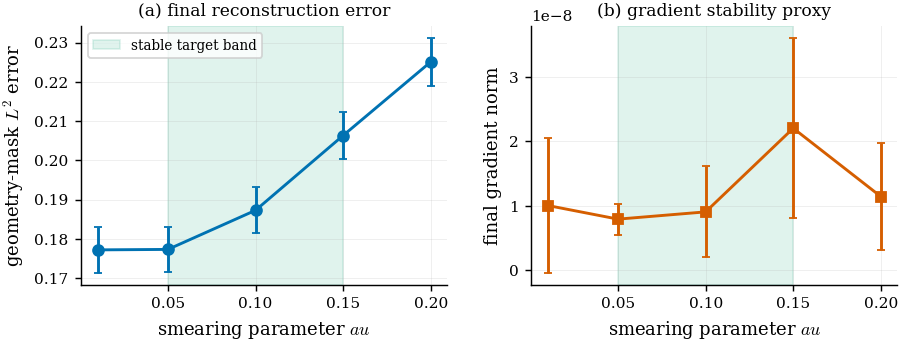

In [4]:
old_tau = divino.TAU
rows, rec_store, traj_store = [], {}, {}
span = np.array([RNG[k][1]-RNG[k][0] for k in PN6])
t0_all = time.time()
try:
    for tau in CFG['TAU_VALUES']:
        divino.TAU = float(tau)
        recs, fits, grad_last, geom_err = [], [], [], []
        print(f'tau={tau:.4g}: inverse repetitions...')
        for rep in range(CFG['REVIEW_INV_REPS']):
            rec, fit, traj = recover(TRUTH, JOBS, CFG['NOISE_SIGMA'], CFG['REVIEW_INV_STEPS'], seed=1000+rep)
            rec = np.array(rec, dtype=float)
            recs.append(rec); fits.append(fit); geom_err.append(geom_l2(rec, TRUTH))
            grad_last.append(float(traj[-1, -1]) if len(traj) else np.nan)
            traj_store[(tau, rep)] = traj
        recs = np.vstack(recs)
        rec_store[tau] = recs
        perr = np.linalg.norm((recs - np.array(TRUTH))/span, axis=1) / math.sqrt(len(PN6))
        rows.append(dict(tau=tau, reps=len(recs), geom_L2_mean=np.mean(geom_err), geom_L2_std=np.std(geom_err),
                         param_norm_L2_mean=np.mean(perr), param_norm_L2_std=np.std(perr),
                         fit_mse_mean=np.mean(fits), fit_mse_std=np.std(fits),
                         grad_norm_final_mean=np.nanmean(grad_last), grad_norm_final_std=np.nanstd(grad_last),
                         cx_mean=recs[:,0].mean(), cy_mean=recs[:,1].mean(), r_mean=recs[:,2].mean(),
                         a_mean=recs[:,3].mean(), phi_mean=recs[:,4].mean(), h_mean=recs[:,5].mean()))
finally:
    divino.TAU = old_tau

T_tau = pd.DataFrame(rows)
savetab(T_tau.round(6), 'T_tau_sensitivity')
np.savez(DATDIR / 'tau_recoveries.npz', **{f'tau_{str(k).replace(".","p")}': v for k,v in rec_store.items()})
display(T_tau.round(5))
print('tau sweep wall time %.1fs' % (time.time() - t0_all))

fig, ax = plt.subplots(1, 2, figsize=(COL2, 2.9))
ax[0].errorbar(T_tau.tau, T_tau.geom_L2_mean, yerr=T_tau.geom_L2_std, marker='o', color=OKABE[0], capsize=2)
ax[0].axvspan(0.05, 0.15, color=OKABE[2], alpha=0.12, label=r'stable target band')
ax[0].set_xlabel(r'smearing parameter $\tau$'); ax[0].set_ylabel('geometry-mask $L^2$ error')
ax[0].legend(fontsize=7.5); ax[0].set_title('(a) final reconstruction error', fontsize=9.5)
ax[1].errorbar(T_tau.tau, T_tau.grad_norm_final_mean, yerr=T_tau.grad_norm_final_std, marker='s', color=OKABE[1], capsize=2)
ax[1].axvspan(0.05, 0.15, color=OKABE[2], alpha=0.12)
ax[1].set_xlabel(r'smearing parameter $\tau$'); ax[1].set_ylabel('final gradient norm')
ax[1].set_title('(b) gradient stability proxy', fontsize=9.5)
plt.tight_layout(); savefig(fig, 'F_tau_sensitivity'); plt.show()

## 3. Local-minima sensitivity from multi-start inverse runs

This table reports dispersion over repeated inverse optimizations. It is the requested standard deviation evidence for non-convex initialization sensitivity.

,tau,parameter,true,mean,std,abs_error,normalized_std
0,0.1,cx,0.460,0.49928,0.00240,0.03928,0.00600
1,0.1,cy,0.500,0.52101,0.00268,0.02101,0.00669
2,0.1,r,0.175,0.17634,0.00110,0.00134,0.00920
3,0.1,a,6.500,5.07930,0.00665,1.42070,0.00111
4,0.1,phi,0.600,0.79104,0.00125,0.19104,0.00080
5,0.1,h,4.000,4.43974,0.03093,0.43974,0.00387


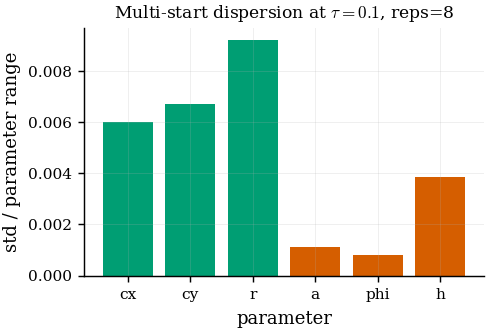

In [5]:
base_tau = 0.10 if 0.10 in rec_store else min(rec_store.keys(), key=lambda x: abs(x-0.10))
recs = rec_store[base_tau]
local_rows = []
for i,k in enumerate(PN6):
    err = recs[:,i] - TRUTH[i]
    local_rows.append(dict(tau=base_tau, parameter=k, true=TRUTH[i], mean=recs[:,i].mean(), std=recs[:,i].std(),
                           abs_error=abs(recs[:,i].mean()-TRUTH[i]), normalized_std=recs[:,i].std()/span[i]))
T_local = pd.DataFrame(local_rows)
savetab(T_local.round(6), 'T_local_minima_multistart')
display(T_local.round(5))

fig, ax = plt.subplots(figsize=(COL1+0.5, 2.8))
ax.bar(T_local.parameter, T_local.normalized_std, color=[OKABE[2] if k in ('cx','cy','r') else OKABE[1] for k in T_local.parameter])
ax.set_ylabel('std / parameter range'); ax.set_xlabel('parameter')
ax.set_title(f'Multi-start dispersion at $\\tau={base_tau:g}$, reps={len(recs)}', fontsize=9.5)
plt.tight_layout(); savefig(fig, 'F_local_minima_multistart'); plt.show()

## 4. OOD star and triangle cavities

The trained operator consumes grid channels, so this diagnostic bypasses the super-ellipse parameter encoder and feeds OOD masks directly. A polygon FEM reference is constructed with the same square boundary conditions and cavity Robin term.

Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.


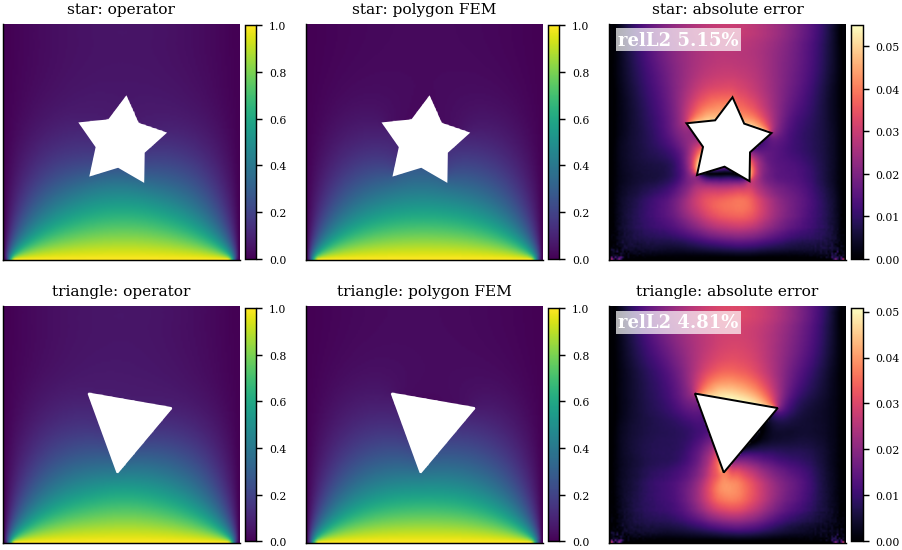

,geometry,relL2,relL2_pct,fem_nodes,fem_tris
0,star,0.05146,5.14624,6752,13067
1,triangle,0.04815,4.81481,6766,13112


In [6]:
def polygon_signed_distance(Xg, Yg, poly):
    pts = np.stack([Xg.ravel(), Yg.ravel()], 1)
    inside = mpath.Path(poly).contains_points(pts).reshape(Xg.shape)
    dmin = np.full(Xg.shape, np.inf)
    for a,b in zip(poly, np.roll(poly, -1, axis=0)):
        axp, ayp = a; bxp, byp = b
        vx, vy = bxp-axp, byp-ayp
        wx, wy = Xg-axp, Yg-ayp
        t = np.clip((wx*vx + wy*vy)/(vx*vx + vy*vy + 1e-12), 0, 1)
        px, py = axp + t*vx, ayp + t*vy
        dmin = np.minimum(dmin, np.sqrt((Xg-px)**2 + (Yg-py)**2))
    return np.where(inside, -dmin, dmin)

def star_poly(cx=0.5, cy=0.5, r1=0.19, r2=0.105, n=5, rot=0.2):
    t = np.linspace(0, 2*np.pi, 2*n, endpoint=False) + rot
    rr = np.where(np.arange(2*n) % 2 == 0, r1, r2)
    return np.stack([cx + rr*np.cos(t), cy + rr*np.sin(t)], 1)

def triangle_poly(cx=0.52, cy=0.50, r=0.205, rot=0.35):
    t = np.linspace(0, 2*np.pi, 3, endpoint=False) + rot
    return np.stack([cx + r*np.cos(t), cy + r*np.sin(t)], 1)

def build_mesh_polygon(poly, hf=0.012, seed=0):
    rng = np.random.default_rng(seed)
    n = int(round(1/hf)); e = np.linspace(0, 1, n+1)
    sq = np.concatenate([np.stack([e, np.zeros_like(e)],1), np.stack([e, np.ones_like(e)],1),
                         np.stack([np.zeros_like(e), e],1), np.stack([np.ones_like(e), e],1)])
    per = np.sqrt(((np.roll(poly,-1,axis=0)-poly)**2).sum(1)).sum()
    nb = max(60, int(per/hf))
    pp = []
    seglen = np.sqrt(((np.roll(poly,-1,axis=0)-poly)**2).sum(1))
    for a,b,L in zip(poly, np.roll(poly,-1,axis=0), seglen):
        m = max(2, int(nb*L/per))
        tt = np.linspace(0, 1, m, endpoint=False)[:,None]
        pp.append(a*(1-tt) + b*tt)
    cavb = np.vstack(pp)
    g = np.linspace(hf, 1-hf, n-1); gx, gy = np.meshgrid(g,g)
    ip = np.stack([gx.ravel(), gy.ravel()],1) + (rng.random((gx.size,2))-0.5)*hf*0.5
    inside = mpath.Path(poly).contains_points(ip)
    pts = np.unique(np.round(np.vstack([sq, cavb, ip[~inside]]), 9), axis=0)
    tri = Delaunay(pts); cent = pts[tri.simplices].mean(1)
    ins = mpath.Path(poly).contains_points(cent)
    return MeshTri(pts.T, tri.simplices[~ins].T.copy())

def solve_fem_polygon(poly, Q0=0.0, h=0.0, Tinf=0.0, hf=0.012, Nout=200):
    m = build_mesh_polygon(poly, hf=hf); e = ElementTriP1(); basis = Basis(m, e)
    K = asm(BilinearForm(lambda u,v,w: dot(grad(u), grad(v))), basis)
    b = asm(LinearForm(lambda v,w: Q0*v), basis) if Q0 != 0 else np.zeros(basis.N)
    bf = m.boundary_facets(); mid = m.p[:, m.facets[:, bf]].mean(1)
    onsq = (mid[0] < 1e-7) | (mid[0] > 1-1e-7) | (mid[1] < 1e-7) | (mid[1] > 1-1e-7)
    cav_facets = bf[~onsq]
    if h > 0 and cav_facets.size:
        fb = FacetBasis(m, e, facets=cav_facets)
        K = K + asm(BilinearForm(lambda u,v,w: h*u*v), fb)
        b = b + asm(LinearForm(lambda v,w: h*Tinf*v), fb)
    x,y = m.p; tol = 1e-7
    bot = np.where(y < tol)[0]; sides = np.where((x < tol) | (x > 1-tol))[0]
    D = np.unique(np.concatenate([bot, sides])); xb = np.zeros(basis.N); xb[bot] = fem.theta_bottom(x[bot])
    theta = solve(*condense(K, b, x=xb, D=D))
    xs = np.linspace(0,1,Nout); Xg,Yg = np.meshgrid(xs,xs)
    tri = mtri.Triangulation(m.p[0], m.p[1], m.t.T)
    interp = mtri.LinearTriInterpolator(tri, theta)
    Tg = np.asarray(interp(Xg.ravel(), Yg.ravel()).reshape(Nout,Nout).filled(np.nan))
    return Tg, m

def fno_field_from_phi(phi_np, Q0=0.0, h=0.0, tau=None):
    tau = divino.TAU if tau is None else tau
    Xn = X.detach().cpu().numpy(); Yn = Y.detach().cpu().numpy()
    smask = 1/(1+np.exp(-phi_np/tau))
    inp_np = np.stack([Xn*2-1, Yn*2-1, smask, np.tanh(phi_np/0.1), np.full_like(phi_np, Q0/3), np.full_like(phi_np, h/8)], 0)[None]
    inp = torch.tensor(inp_np, dtype=torch.float32, device=DEV)
    with torch.no_grad():
        th = divino.hard_bc(MODEL(inp), Dm, Dv)[0].detach().cpu().numpy()
    th[phi_np < 0] = np.nan
    return th

ood_cases = {'star': star_poly(), 'triangle': triangle_poly()}
rows = []
fig, ax = plt.subplots(len(ood_cases), 3, figsize=(COL2, 4.5))
for row, (name, poly) in enumerate(ood_cases.items()):
    XgN, YgN = np.meshgrid(np.linspace(0,1,N), np.linspace(0,1,N))
    phiN = polygon_signed_distance(XgN, YgN, poly)
    pr = fno_field_from_phi(phiN, h=4.0, tau=0.10)
    rf, mesh = solve_fem_polygon(poly, h=4.0, hf=CFG['FEM_HF'], Nout=N)
    err = np.abs(pr-rf); mk = (~np.isnan(pr)) & (~np.isnan(rf)) & (phiN > 2.5*DX)
    rel = float(np.sqrt(np.mean((pr-rf)[mk]**2))/(np.sqrt(np.mean(rf[mk]**2))+1e-12))
    rows.append(dict(geometry=name, relL2=rel, relL2_pct=100*rel, fem_nodes=mesh.p.shape[1], fem_tris=mesh.t.shape[1]))
    vmin, vmax = np.nanmin(rf), np.nanmax(rf)
    for j,(U,cm,title) in enumerate([(pr,CMAP_T,'operator'), (rf,CMAP_T,'polygon FEM'), (err,CMAP_E,'absolute error')]):
        im = ax[row,j].imshow(U, origin='lower', extent=[0,1,0,1], cmap=cm, norm=(Normalize(vmin,vmax) if j < 2 else None), interpolation='bilinear')
        ax[row,j].add_patch(mpatches.Polygon(poly, closed=True, facecolor='white', edgecolor=('w' if j<2 else 'k'), lw=1.1, zorder=5))
        ax[row,j].set_xticks([]); ax[row,j].set_yticks([]); ax[row,j].set_title(f'{name}: {title}', fontsize=8.5)
        fig.colorbar(im, ax=ax[row,j], fraction=0.046, pad=0.02).ax.tick_params(labelsize=6)
    panel_label(ax[row,2], f'relL2 {100*rel:.2f}%', x=0.04, y=0.97, c='w')
plt.tight_layout(); savefig(fig, 'F_ood_star_triangle'); plt.show()
T_ood = savetab(pd.DataFrame(rows).round(5), 'T_ood_star_triangle')
display(T_ood)

## 5. Robustness to spatially correlated noise

This compares the existing independent Gaussian noise benchmark to a Gaussian-process-like exponential covariance along the top sensor line.

Transforming over 1000 vertices to C_CONTIGUOUS.


,noise_model,sigma,corr_length,param,mean,std,abs_error,err_norm,std_norm
0,white,0.01,0.00,cx,0.49859,0.00201,0.03859,0.09647,0.00503
1,white,0.01,0.00,cy,0.50648,0.00150,0.00648,0.01620,0.00376
2,white,0.01,0.00,r,0.16577,0.00122,0.00923,0.07692,0.01017
3,white,0.01,0.00,a,5.02903,0.00629,1.47097,0.24516,0.00105
4,white,0.01,0.00,phi,0.78675,0.00047,0.18675,0.11889,0.00030
5,white,0.01,0.00,h,4.18513,0.03690,0.18513,0.02314,0.00461
6,correlated,0.01,0.12,cx,0.49643,0.00684,0.03643,0.09107,0.01709
7,correlated,0.01,0.12,cy,0.51088,0.00310,0.01088,0.02720,0.00774
8,correlated,0.01,0.12,r,0.16891,0.00207,0.00609,0.05074,0.01727
9,correlated,0.01,0.12,a,5.04666,0.01201,1.45334,0.24222,0.00200


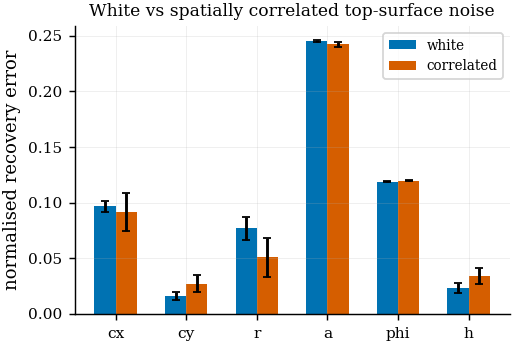

In [7]:
def correlated_noise(jcols, sigma=0.01, ell=0.12, rng=None):
    rng = np.random.default_rng(0) if rng is None else rng
    x = jcols/(N-1)
    C = sigma**2 * np.exp(-np.abs(x[:,None]-x[None,:])/ell)
    C += 1e-10*np.eye(len(jcols))
    return rng.multivariate_normal(np.zeros(len(jcols)), C)

clean = top_obs_fem(TRUTH, JOBS, 0.0, np.random.default_rng(10))
noise_rows = []
for kind in ['white', 'correlated']:
    recs = []
    for rep in range(CFG['REVIEW_INV_REPS']):
        rng = np.random.default_rng(2000+rep)
        if kind == 'white':
            obs = clean + rng.normal(0, CFG['NOISE_SIGMA'], len(JOBS))
        else:
            obs = clean + correlated_noise(JOBS, CFG['NOISE_SIGMA'], CFG['CORR_LENGTH'], rng)
        rec, fit, traj = recover_from_obs(obs, JOBS, CFG['REVIEW_INV_STEPS'], seed=3000+rep)
        recs.append(rec)
    recs = np.array(recs, dtype=float)
    for i,k in enumerate(PN6):
        noise_rows.append(dict(noise_model=kind, sigma=CFG['NOISE_SIGMA'], corr_length=(CFG['CORR_LENGTH'] if kind=='correlated' else 0.0),
                               param=k, mean=recs[:,i].mean(), std=recs[:,i].std(),
                               abs_error=abs(recs[:,i].mean()-TRUTH[i]),
                               err_norm=abs(recs[:,i].mean()-TRUTH[i])/span[i], std_norm=recs[:,i].std()/span[i]))
T_corr = pd.DataFrame(noise_rows)
savetab(T_corr.round(6), 'T_correlated_noise')
display(T_corr.round(5))

fig, ax = plt.subplots(figsize=(COL1+0.7, 2.9))
for kind,c,off in [('white',OKABE[0],-0.15), ('correlated',OKABE[1],0.15)]:
    d = T_corr[T_corr.noise_model == kind]
    x = np.arange(len(PN6)) + off
    ax.bar(x, d.err_norm, width=0.3, yerr=d.std_norm, color=c, capsize=2, label=kind)
ax.set_xticks(np.arange(len(PN6))); ax.set_xticklabels(PN6)
ax.set_ylabel(r'normalised recovery error')
ax.set_title('White vs spatially correlated top-surface noise', fontsize=9.5)
ax.legend(fontsize=7.5)
plt.tight_layout(); savefig(fig, 'F_correlated_noise'); plt.show()

## 6. FNO training/inference vs adjoint-FEM break-even timing

The adjoint baseline is modeled as one forward plus one adjoint FEM solve per optimization iteration. If `TRAIN_TIME_S` is not supplied, the table uses the checkpoint training-step count and reports the training time as unavailable, while still giving the measured inference and FEM per-iteration costs. For a paper-ready break-even table, set `TRAIN_TIME_S` to the measured wall time of the original FNO training run.

Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.


,reconstruction_trials,fno_training_s,fno_inference_per_forward_ms,fem_forward_solve_ms,adjoint_iters,fno_total_s,adjoint_fem_total_s,fno_speedup_total
0,1,NaN,1.4561,61.2054,100,NaN,12.2411,NaN
1,10,NaN,1.4561,61.2054,100,NaN,122.4108,NaN
2,100,NaN,1.4561,61.2054,100,NaN,1224.1077,NaN
3,1000,NaN,1.4561,61.2054,100,NaN,12241.0774,NaN


Measured FEM solve 61.2 ms, FNO forward 1.456 ms, break-even trials: set TRAIN_TIME_S


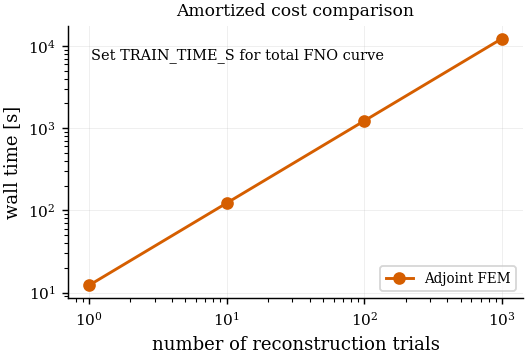

In [8]:
def time_fno_inference(case, repeats=50):
    p = divino.case_to_params(case, DEV); inp, _, _ = divino.channels_from_params(p, X, Y)
    if DEV.type == 'cuda': torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(repeats):
        with torch.no_grad(): _ = MODEL(inp)
    if DEV.type == 'cuda': torch.cuda.synchronize()
    return (time.time()-t0)/repeats

def time_fem_solve(case, reps=3):
    t0 = time.time()
    for r in range(reps):
        _ = fem.solve_fem(case, hf=CFG['FEM_HF'])
    return (time.time()-t0)/reps

timing_case = case_of(TRUTH)
t_fno = time_fno_inference(timing_case, repeats=50)
t_fem = time_fem_solve(timing_case, reps=3)
train_s = CFG['TRAIN_TIME_S']
trials = [1, 10, 100, 1000]
rows = []
for nr in trials:
    fno_total = (0.0 if np.isnan(train_s) else train_s) + nr * CFG['REVIEW_INV_STEPS'] * t_fno
    adj_total = nr * CFG['ADJOINT_ITERS'] * 2 * t_fem
    rows.append(dict(reconstruction_trials=nr, fno_training_s=train_s, fno_inference_per_forward_ms=1e3*t_fno,
                     fem_forward_solve_ms=1e3*t_fem, adjoint_iters=CFG['ADJOINT_ITERS'],
                     fno_total_s=(np.nan if np.isnan(train_s) else fno_total), adjoint_fem_total_s=adj_total,
                     fno_speedup_total=(np.nan if np.isnan(train_s) else adj_total/fno_total)))
T_break = pd.DataFrame(rows)
if not np.isnan(train_s):
    denom = max(CFG['ADJOINT_ITERS']*2*t_fem - CFG['REVIEW_INV_STEPS']*t_fno, 1e-12)
    break_even = train_s / denom
else:
    break_even = np.nan
savetab(T_break.round(4), 'T_adjoint_fem_break_even')
display(T_break.round(4))
print('Measured FEM solve %.1f ms, FNO forward %.3f ms, break-even trials: %s' % (1e3*t_fem, 1e3*t_fno, 'set TRAIN_TIME_S' if np.isnan(break_even) else f'{break_even:.1f}'))

fig, ax = plt.subplots(figsize=(COL1+0.8, 3.0))
ax.loglog(T_break.reconstruction_trials, T_break.adjoint_fem_total_s, 'o-', color=OKABE[1], label='Adjoint FEM')
if not np.isnan(train_s):
    ax.loglog(T_break.reconstruction_trials, T_break.fno_total_s, 's-', color=OKABE[0], label='FNO train + inverse')
    ax.axvline(break_even, color='0.35', ls=':', label=f'break-even {break_even:.1f}')
else:
    ax.text(0.05, 0.92, 'Set TRAIN_TIME_S for total FNO curve', transform=ax.transAxes, fontsize=8, va='top')
ax.set_xlabel('number of reconstruction trials'); ax.set_ylabel('wall time [s]')
ax.set_title('Amortized cost comparison', fontsize=9.5); ax.legend(fontsize=7.5)
plt.tight_layout(); savefig(fig, 'F_adjoint_fem_break_even'); plt.show()

## 7. Cut-cell / perimeter-correction consistency

This isolates the `L_analytic / L_stair` correction used by the Cartesian energy. The expected behavior is first-order convergence of the staircase perimeter to the analytic perimeter as the grid is refined.

,N,dx,L_analytic,L_stair,rel_perimeter_error,correction_factor
0,32,0.032258,1.26318,1.612903,0.276860,0.783171
1,48,0.021277,1.26318,1.531915,0.212745,0.824576
2,64,0.015873,1.26318,1.555556,0.231460,0.812044
3,96,0.010526,1.26318,1.600000,0.266645,0.789487
4,128,0.007874,1.26318,1.590551,0.259165,0.794177
5,192,0.005236,1.26318,1.591623,0.260013,0.793642
6,256,0.003922,1.26318,1.592157,0.260436,0.793376


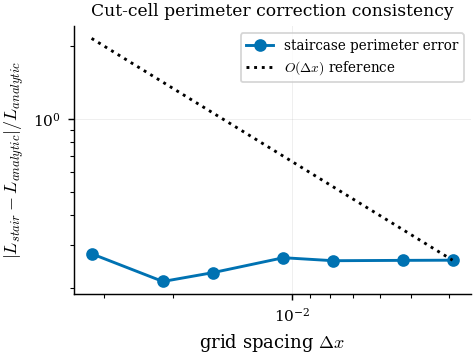

In [9]:
def staircase_perimeter(theta, Ng):
    xs = np.linspace(0,1,Ng); Xg,Yg = np.meshgrid(xs,xs); dx = 1/(Ng-1)
    M = (divino.cav_phi_np(Xg,Yg,g5(theta)) > 0).astype(float)
    solid = 1.0 - M
    faces = np.zeros_like(M)
    faces[:, :-1] += solid[:, 1:]; faces[:, 1:] += solid[:, :-1]
    faces[:-1, :] += solid[1:, :]; faces[1:, :] += solid[:-1, :]
    band = M * (faces > 0)
    return float((faces * band).sum() * dx)

theta_cc = (0.48,0.5,0.18,4.0,0.3,4.0)
La = divino.superellipse_perimeter_np(theta_cc[2], theta_cc[3])
Ns = np.array([32,48,64,96,128,192,256])
Ls = np.array([staircase_perimeter(theta_cc, int(n)) for n in Ns])
Terr = np.abs(Ls-La)/La
T_cut = pd.DataFrame(dict(N=Ns, dx=1/(Ns-1), L_analytic=La, L_stair=Ls, rel_perimeter_error=Terr, correction_factor=np.clip(La/Ls,0.3,1.0)))
savetab(T_cut.round(7), 'T_cutcell_perimeter_convergence')
display(T_cut.round(6))

fig, ax = plt.subplots(figsize=(COL1+0.4, 3.0))
ax.loglog(T_cut.dx, T_cut.rel_perimeter_error, 'o-', color=OKABE[0], label='staircase perimeter error')
ref = T_cut.rel_perimeter_error.iloc[-1]*(T_cut.dx/T_cut.dx.iloc[-1])
ax.loglog(T_cut.dx, ref, 'k:', label=r'$O(\Delta x)$ reference')
ax.invert_xaxis(); ax.set_xlabel(r'grid spacing $\Delta x$'); ax.set_ylabel(r'$|L_{stair}-L_{analytic}|/L_{analytic}$')
ax.set_title('Cut-cell perimeter correction consistency', fontsize=9.5); ax.legend(fontsize=7.5)
plt.tight_layout(); savefig(fig, 'F_cutcell_perimeter_convergence'); plt.show()

## 8. Two-hole proximity diagnostic

This is a small support test for the multi-hole/topological-transition discussion. It does not claim a rigorous merging/splitting stability proof; it measures forward accuracy as two cavities approach one another.

Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 vertices to C_CONTIGUOUS.


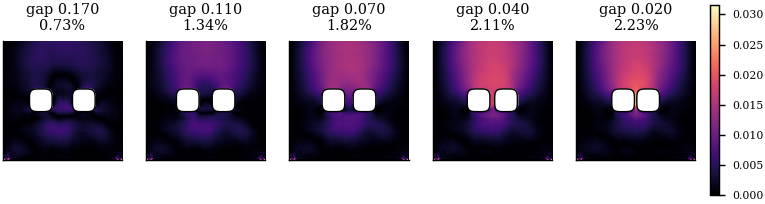

,center_separation,nominal_gap,relL2,relL2_pct
0,0.36,0.17,0.00726,0.72642
1,0.30,0.11,0.01338,1.33818
2,0.26,0.07,0.01816,1.81625
3,0.23,0.04,0.02113,2.11335
4,0.21,0.02,0.02232,2.23213


In [10]:
def masked_multi(field, cavs, Nout):
    Xg,Yg = np.meshgrid(np.linspace(0,1,Nout), np.linspace(0,1,Nout))
    f = field.copy()
    for c in cavs: f[divino.cav_phi_np(Xg,Yg,c) < 0] = np.nan
    return f

rows = []
seps = np.array([0.36,0.30,0.26,0.23,0.21])
fig, ax = plt.subplots(1, len(seps), figsize=(COL2, 1.9))
for j,sep in enumerate(seps):
    c1 = (0.5-sep/2, 0.50, 0.095, 4.0, 0.0)
    c2 = (0.5+sep/2, 0.50, 0.095, 4.0, 0.0)
    case = {'cavities':[c1,c2], 'Q0':0.0, 'h':4.0, 'Tinf':0.0}
    pr = masked_multi(fno_field(case, N), [c1,c2], N)
    rf = masked_multi(fem_field(case, N, hf=CFG['FEM_HF']), [c1,c2], N)
    Xg,Yg = np.meshgrid(np.linspace(0,1,N), np.linspace(0,1,N))
    mk = (~np.isnan(pr)) & (~np.isnan(rf))
    for c in [c1,c2]: mk &= divino.cav_phi_np(Xg,Yg,c) > 2.5*DX
    rel = float(np.sqrt(np.mean((pr-rf)[mk]**2))/(np.sqrt(np.mean(rf[mk]**2))+1e-12))
    gap = sep - c1[2] - c2[2]
    rows.append(dict(center_separation=sep, nominal_gap=gap, relL2=rel, relL2_pct=100*rel))
    im = ax[j].imshow(np.abs(pr-rf), origin='lower', extent=[0,1,0,1], cmap=CMAP_E, interpolation='bilinear')
    for c in [c1,c2]: draw_cavity(ax[j], c, ec='k', lw=0.8)
    ax[j].set_title(f'gap {gap:.3f}\n{100*rel:.2f}%', fontsize=8)
    ax[j].set_xticks([]); ax[j].set_yticks([]); ax[j].grid(False)
fig.colorbar(im, ax=ax.ravel().tolist(), fraction=0.025, pad=0.02).ax.tick_params(labelsize=6)
savefig(fig, 'F_two_hole_proximity'); plt.show()
T_two = savetab(pd.DataFrame(rows).round(5), 'T_two_hole_proximity')
display(T_two)

In [11]:
figs = sorted(FIGDIR.glob('*.pdf'))
tabs = sorted(TABDIR.glob('*.csv'))
print(f'{FIGDIR} ({len(figs)} pdf figures):')
for f in figs: print('  ', f.name)
print(f'{TABDIR} ({len(tabs)} csv tables):')
for t in tabs: print('  ', t.name)

../results/figures (7 pdf figures):
   F_adjoint_fem_break_even.pdf
   F_correlated_noise.pdf
   F_cutcell_perimeter_convergence.pdf
   F_local_minima_multistart.pdf
   F_ood_star_triangle.pdf
   F_tau_sensitivity.pdf
   F_two_hole_proximity.pdf
../results/tables (7 csv tables):
   T_adjoint_fem_break_even.csv
   T_correlated_noise.csv
   T_cutcell_perimeter_convergence.csv
   T_local_minima_multistart.csv
   T_ood_star_triangle.csv
   T_tau_sensitivity.csv
   T_two_hole_proximity.csv
